# Ecoverse 813 — main analysis
**Theme 05 · Sustainable Urban Planning & Smart Cities** · Arab Youth Space Hackathon: 813 Challenge

**Problem statement.** *We want to **identify** the lowest-maintenance native plant combination that can survive each 20 m patch of
**northern-central Bahrain** (Manama – Tubli Bay – Isa Town – Sitra) under **summer 2025** conditions, so that **municipal
landscaping planners** can decide **what to plant (or replant) where**, instead of keeping unsuitable trees alive with irrigation.*

**What this notebook does (in order)**
1. Loads the committed, clipped open-data stack (Sentinel-2, Landsat thermal, Copernicus DEM, ESA WorldCover).
2. Pulls in the *hyperspectral calibration* learned on open Planet Tanager Gulf scenes (notebook 01).
3. Builds the **environmental fingerprint**: heat, salinity, saline groundwater, moisture, survival evidence, irrigation dependence, urban density.
4. Scores 26 species (21 native/adapted + 5 common urban plantings) for survival, then picks the **lowest-water, lowest-upkeep guild** (canopy + shrub + groundcover).
5. Estimates **irrigation water saved** vs. today's typical Conocarpus + lawn planting.
6. Runs a **Monte Carlo robustness test** and plans **where two students with a low-cost probe should measure next**.
7. Validates what can be validated, and states limitations.

Runtime ≈ 2–4 min on a laptop, no GPU. Inputs: `data/sample_input/`. Outputs: `results/`.

In [1]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=RuntimeWarning)   # all-NaN medians at scene edges

from ecoverse import config, io, fingerprint, plants, recommend, uncertainty, hyperspectral, viz, report
np.random.seed(config.RANDOM_SEED)
pd.set_option("display.width", 160, "display.max_columns", 20, "display.precision", 3)
print("Repository root:", ROOT.name)
print("Results folder :", config.RESULTS_DIR.relative_to(ROOT) if config.RESULTS_DIR.is_relative_to(ROOT) else config.RESULTS_DIR)

Repository root: ecoverse-final
Results folder : results


## 1 · Load the input stack and its provenance

In [2]:
if not config.STACK_TIF.exists():
    raise FileNotFoundError(f"{config.STACK_TIF} missing - run `python scripts/fetch_data.py` (see README)")
layers, profile = io.read_stack(config.STACK_TIF)
meta = json.loads(config.STACK_META.read_text())
if meta.get("synthetic") and os.environ.get("ECOVERSE_ALLOW_SYNTHETIC") != "1":
    raise RuntimeError("Synthetic test fixture detected - refusing to produce results from it.")
RES = abs(profile["transform"].a)
print(f"AOI   : {meta['aoi']['name']}")
print(f"Grid  : {profile['width']} x {profile['height']} px at {RES:.0f} m, {profile['crs']}")
print(f"Layers: {', '.join(layers)}")
prov = pd.DataFrame([{"source": k, "collection": v.get("collection"), "period": v.get("period", "-"),
                      "scenes": v.get("n_scenes", len(v.get("item_ids", [])))} for k, v in meta["sources"].items()])
prov

AOI   : Northern-central Bahrain (Manama - Tubli Bay - Isa Town - Sitra)
Grid  : 703 x 667 px at 20 m, EPSG:32639
Layers: B02, B03, B04, B05, B06, B07, B8A, B11, B12, W_B04, W_B8A, W_B11, VEG_PERSIST, S2_NOBS, LST_SUMMER, DEM, WORLDCOVER


,source,collection,period,scenes
0,sentinel2_summer,sentinel-2-l2a,2025-06-01/2025-08-31,42
1,sentinel2_winter,sentinel-2-l2a,2025-12-01/2026-02-28,24
2,landsat_lst,landsat-c2-l2 (lwir11 surface temperature),2025-06-01/2025-08-31,10
3,dem,cop-dem-glo-30,-,1
4,worldcover,esa-worldcover,-,2


### Quality control
Cloud/shadow pixels were removed scene by scene with the Sentinel-2 SCL mask and the Landsat QA_PIXEL bits before compositing (see `src/ecoverse/fetch.py`). Here we check what is left.

In [3]:
nobs = layers["S2_NOBS"]
qc = {
    "Sentinel-2 valid pixels (%)": 100 * np.isfinite(layers["B04"]).mean(),
    "Clear summer observations per pixel (median)": float(np.nanmedian(nobs)),
    "Clear summer observations per pixel (5th pct)": float(np.nanpercentile(nobs, 5)),
    "Landsat LST coverage (%)": 100 * np.isfinite(layers["LST_SUMMER"]).mean(),
    "Summer LST range, 2-98 pct (°C)": f"{np.nanpercentile(layers['LST_SUMMER'],2):.1f} – {np.nanpercentile(layers['LST_SUMMER'],98):.1f}",
    "DEM range (m)": f"{np.nanmin(layers['DEM']):.1f} – {np.nanmax(layers['DEM']):.1f}",
}
pd.Series(qc, name="value").to_frame()

,value
Sentinel-2 valid pixels (%),100.0
Clear summer observations per pixel (median),21.0
Clear summer observations per pixel (5th pct),0.0
Landsat LST coverage (%),100.0
"Summer LST range, 2-98 pct (°C)",31.7 – 55.3
DEM range (m),-11.1 – 57.9


## 2 · Hyperspectral calibration ("hyperspectral teaches multispectral")
Bahrain is not in Tanager's open archive and Satellite 813 data is only available in incubation. Notebook 01 learns, on open Tanager scenes
of Gulf coastal sabkha and an arid Gulf city, which narrow-band signals Sentinel-2 can and cannot reproduce. We only use a transferred
signal in Bahrain if spatially-blocked cross-validation shows Sentinel-2 recovers it well (R² ≥ 0.4). Otherwise the fingerprint falls back
to a Sentinel-2-only SWIR proxy, and the gap is reported as exactly what Satellite 813 must fill.

In [4]:
gypsum_proxy, transfer = None, None
try:
    tdf, tmeta, _ = hyperspectral.load_tanager_tables()
    transfer = hyperspectral.evaluate_transfer(tdf)
    display(transfer.round(3))
    r2 = transfer.set_index("target").loc["GYPSUM_1750", "r2_boosted"]
    if r2 >= 0.4:
        model = hyperspectral.fit_transfer_model(tdf, "GYPSUM_1750")
        gypsum_proxy = hyperspectral.predict_on_s2(model, {k: layers[k] for k in hyperspectral.S2_NAMES})
        print(f"Gypsum (1750 nm) signal recovered from Sentinel-2 with CV R² = {r2:.2f} -> used in the salinity layer")
    else:
        print(f"Gypsum CV R² = {r2:.2f} < 0.4 -> NOT transferred; Sentinel-2 SWIR ratio used instead (gap for Satellite 813)")
except FileNotFoundError as e:
    print("No Tanager calibration data:", e)

,target,pixels,n,r2_linear,r2_boosted,mae_boosted,hyperspectral_only_info_pct
0,GYPSUM_1750,soil,30872,0.507,0.625,0.005,37.510
1,CLAY_2200,soil,30872,0.756,0.892,0.007,10.831
2,CARBONATE_2340,soil,30872,0.779,0.944,0.016,5.596
3,REP,veg,276,0.882,0.500,0.667,50.033
4,CANOPY_WATER_1200,veg,276,0.902,0.811,0.007,18.865


Gypsum (1750 nm) signal recovered from Sentinel-2 with CV R² = 0.62 -> used in the salinity layer


## 3 · The environmental fingerprint

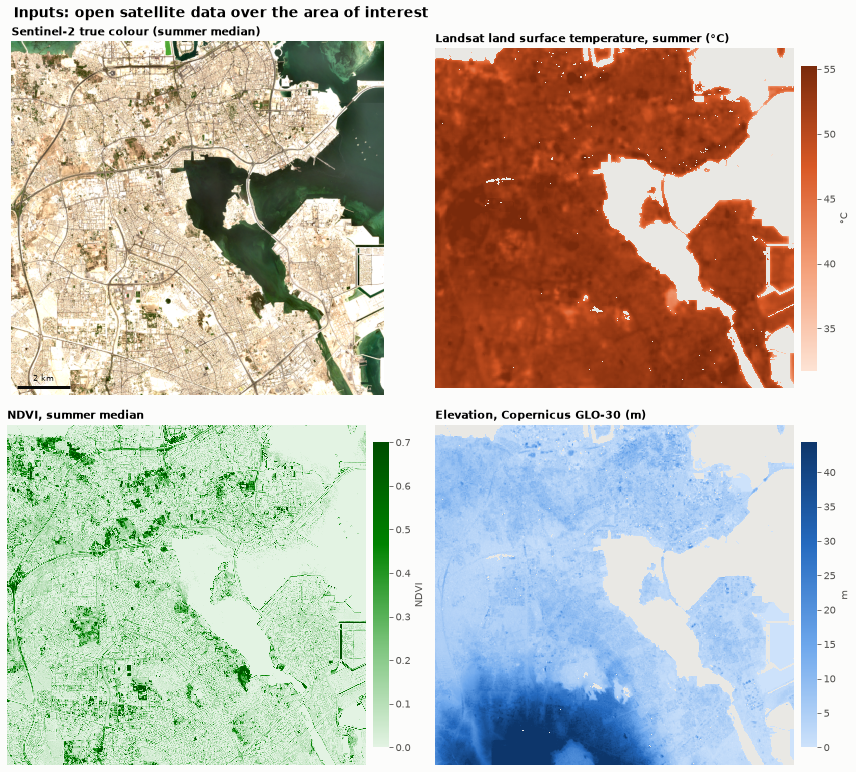

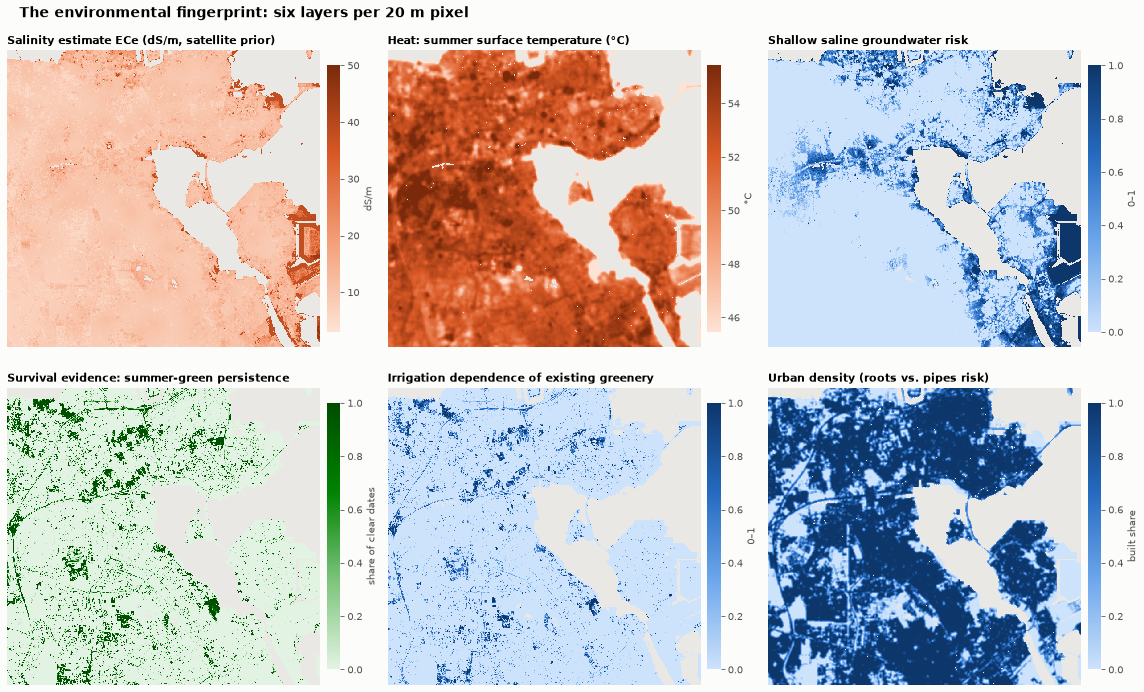

Land pixels: 373,811 (149.5 km²) · intertidal: 11,706 · irrigated greenery today: 27,695 px (1108 ha)


In [5]:
fp = fingerprint.build_fingerprint(layers, res_m=RES, gypsum_proxy=gypsum_proxy)
fig = viz.fig_inputs(layers, fp, RES); viz.save(fig, "01_inputs.png"); plt.show()
fig = viz.fig_fingerprint(fp); viz.save(fig, "02_fingerprint.png"); plt.show()
L = fp["land"]
print(f"Land pixels: {L.sum():,} ({L.sum()*RES*RES/1e6:.1f} km²) · intertidal: {fp['intertidal'].sum():,} · "
      f"irrigated greenery today: {fp['irrigated'].sum():,} px ({fp['irrigated'].sum()*RES*RES/1e4:.0f} ha)")

### Micro-habitat archetypes
Clustering the fingerprint shows the AOI is a patchwork of a few recurring habitats — the unit a planner can reason about.

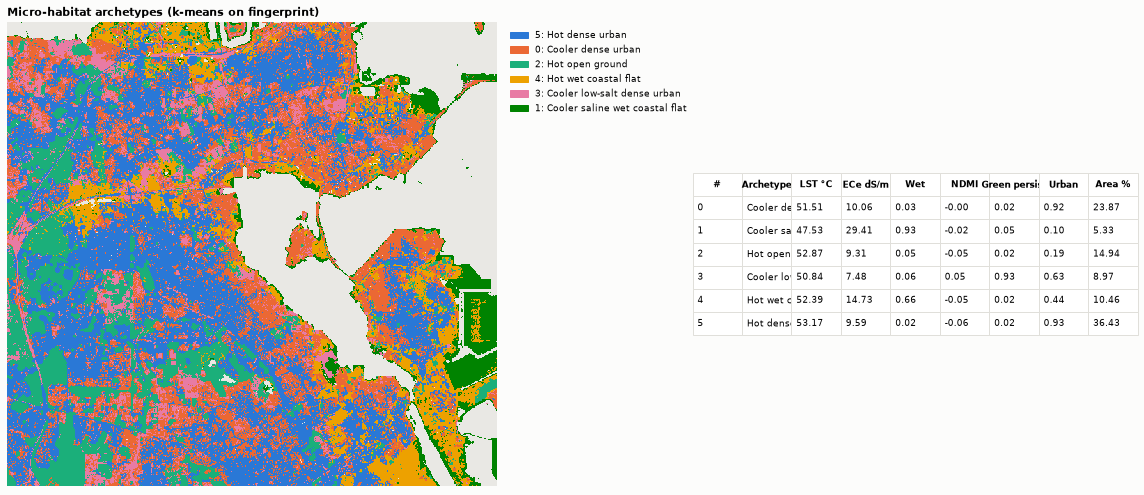

,LST,ECE,WATERLOG,NDMI,VEG_PERSIST,BUILT_DENSITY,share_pct,name
0,51.51,10.06,0.03,-0.00,0.02,0.92,23.87,Cooler dense urban
1,47.53,29.41,0.93,-0.02,0.05,0.10,5.33,Cooler saline wet coastal flat
2,52.87,9.31,0.05,-0.05,0.02,0.19,14.94,Hot open ground
3,50.84,7.48,0.06,0.05,0.93,0.63,8.97,Cooler low-salt dense urban
4,52.39,14.73,0.66,-0.05,0.02,0.44,10.46,Hot wet coastal flat
5,53.17,9.59,0.02,-0.06,0.02,0.93,36.43,Hot dense urban


In [6]:
arche, cent = fingerprint.habitat_archetypes(fp, k=6)
fig = viz.fig_archetypes(arche, cent); viz.save(fig, "03_archetypes.png"); plt.show()
cent.round(2)

## 4 · Survival model and recommendation
Each species gets a 0–1 response curve per factor (salinity vs. its literature ECe comfort/survival limits, heat, drought, waterlogging,
habitat, pH, root-vs-infrastructure risk). Survival = product of curves, so one fatal factor cannot be averaged away.
A species *survives* at ≥ 0.6. Among survivors, the engine minimises water (WUCOLS plant factor) and upkeep, and rewards shade where it is hottest.

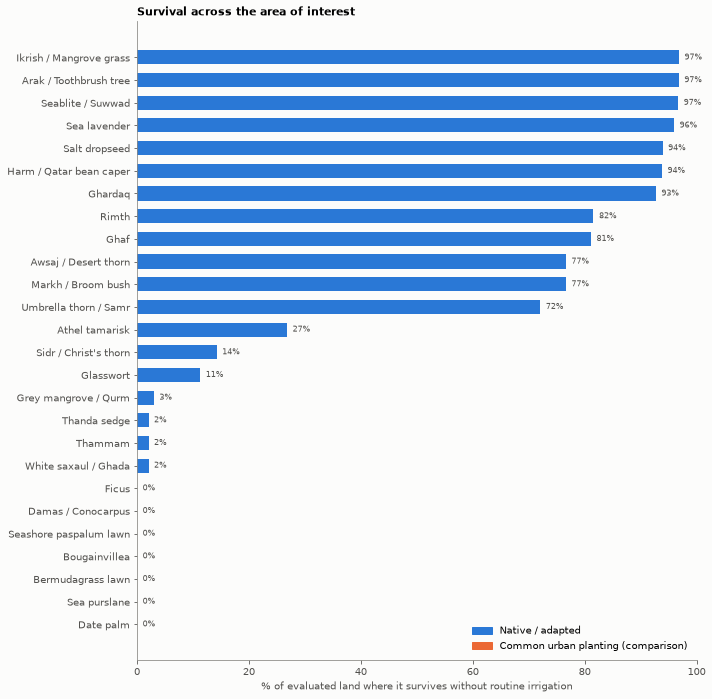

,common_name,layer,plant_factor,survives_pct_area,recommended_pct_area,main_limit_where_fails
0,Arak / Toothbrush tree,shrub,0.1,96.8,96.8,salinity
1,Ghaf,canopy,0.1,81.1,78.2,waterlog
2,Rimth,ground,0.1,81.6,45.2,waterlog
3,Harm / Qatar bean caper,ground,0.1,93.8,33.4,salinity
4,Sea lavender,ground,0.1,96.0,14.1,salinity
5,Athel tamarisk,canopy,0.2,26.8,10.5,infrastructure
6,Glasswort,ground,0.2,11.3,5.7,habitat
7,Grey mangrove / Qurm,canopy,0.0,3.0,3.0,habitat
8,Seablite / Suwwad,ground,0.2,96.7,1.2,salinity
9,Ikrish / Mangrove grass,ground,0.2,96.8,0.5,salinity


In [7]:
kb = plants.load_plants()
res = recommend.run_engine(fp, kb)
summary = recommend.species_summary(res)
summary.to_csv(config.RESULTS_DIR / "species_summary.csv", index=False)
fig = viz.fig_species_bars(summary); viz.save(fig, "04_species_survival.png"); plt.show()
summary[["common_name", "layer", "plant_factor", "survives_pct_area", "recommended_pct_area", "main_limit_where_fails"]].round(1)

In [8]:
guild_id, guilds = recommend.guild_codes(res)
guilds.head(10).round(1)

,guild_id,canopy,shrub,ground,pixels,share_pct
0,7,Ghaf,Arak / Toothbrush tree,Rimth,168815,45.2
1,9,Ghaf,Arak / Toothbrush tree,Harm / Qatar bean caper,117136,31.3
2,13,Athel tamarisk,Arak / Toothbrush tree,Sea lavender,23872,6.4
3,5,—,Arak / Toothbrush tree,Sea lavender,22396,6.0
4,15,Grey mangrove / Qurm,—,Glasswort,11221,3.0
5,14,Athel tamarisk,Arak / Toothbrush tree,Harm / Qatar bean caper,7602,2.0
6,3,—,Arak / Toothbrush tree,Glasswort,6399,1.7
7,8,Ghaf,Arak / Toothbrush tree,Sea lavender,6265,1.7
8,10,Athel tamarisk,Arak / Toothbrush tree,Seablite / Suwwad,3729,1.0
9,11,Athel tamarisk,Arak / Toothbrush tree,Glasswort,2892,0.8


## 5 · Robustness: Monte Carlo over every uncertain input
Salinity (per-pixel log-normal + an AOI-wide calibration shift), heat, waterlogging, pH and ET0 are perturbed; we count how often each pixel keeps the same recommendation.

Median stability 0.93; 88% of land pixels keep the same species in ≥80% of draws


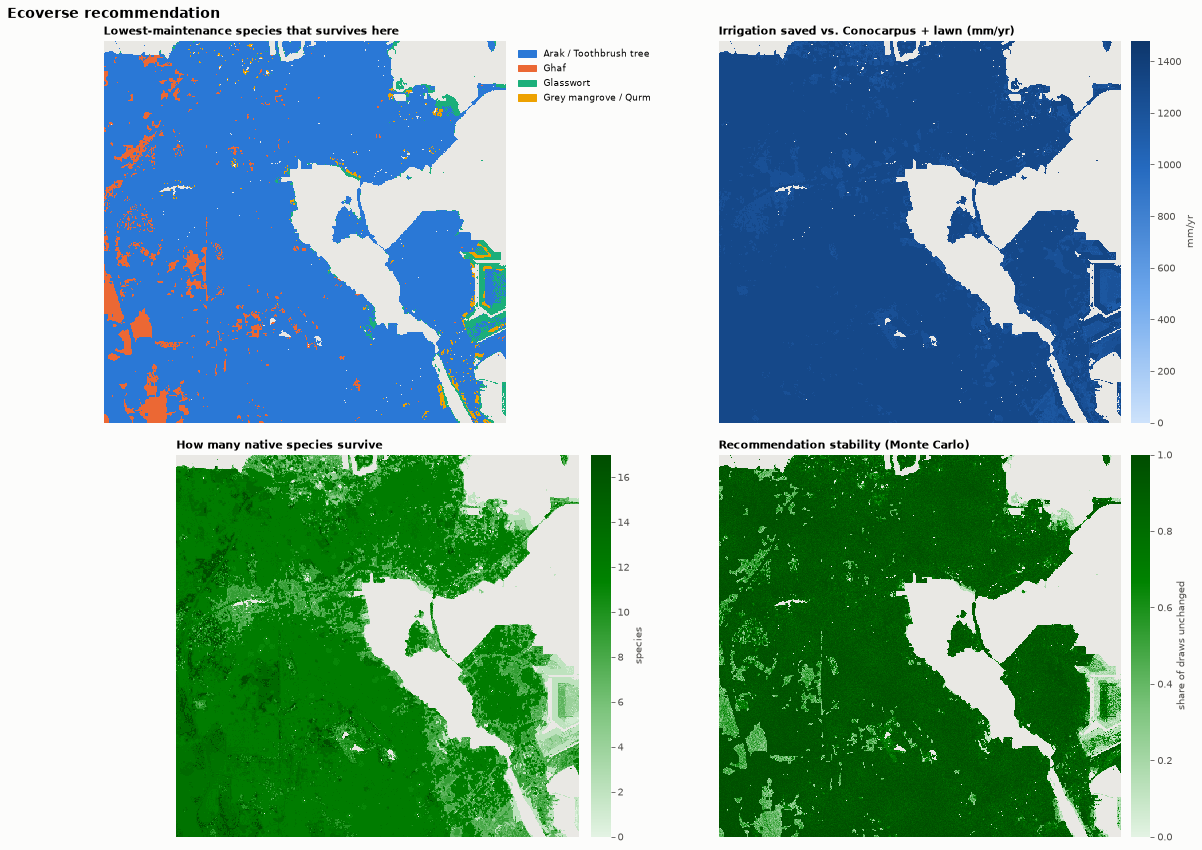

In [9]:
run = config.RunConfig()
stability, draws = uncertainty.monte_carlo(fp, kb, res, n=run.n_monte_carlo, seed=run.seed)
print(f"Median stability {np.median(stability):.2f}; {100*np.mean(stability>=0.8):.0f}% of land pixels keep the same species in ≥80% of draws")
fig = viz.fig_recommendation(res, fp, stability); viz.save(fig, "05_recommendation.png"); plt.show()

## 6 · Water: what this saves

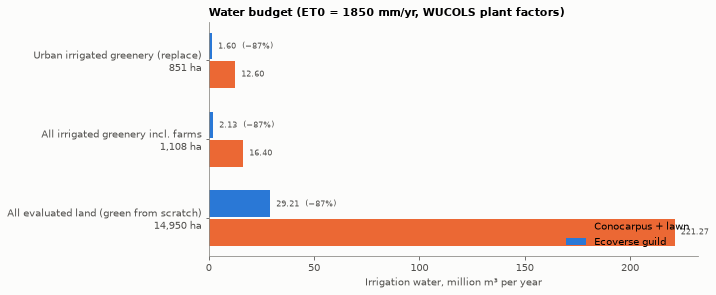

Mean saving per irrigated m²: 1285 mm/yr (90% MC interval 1249–1432)


,scenario,area_ha,baseline_m3_yr,ecoverse_m3_yr,saving_m3_yr,saving_pct
0,Urban irrigated greenery (replace),851.1,1.260e+07,1.597e+06,1.100e+07,87.3
1,All irrigated greenery incl. farms,1107.8,1.640e+07,2.129e+06,1.427e+07,87.0
2,All evaluated land (green from scratch),14950.4,2.213e+08,2.921e+07,1.921e+08,86.8


In [10]:
budget = recommend.water_budget(res, fp, RES)
budget.to_csv(config.RESULTS_DIR / "water_budget.csv", index=False)
fig = viz.fig_water(budget); viz.save(fig, "06_water_budget.png"); plt.show()
lo, hi = np.percentile(draws["mean_saving_mm"], [5, 95])
print(f"Mean saving per irrigated m²: {np.nanmean(res.saving_mm):.0f} mm/yr (90% MC interval {lo:.0f}–{hi:.0f})")
budget.round(1)

## 7 · Site report cards — the product a planner reads

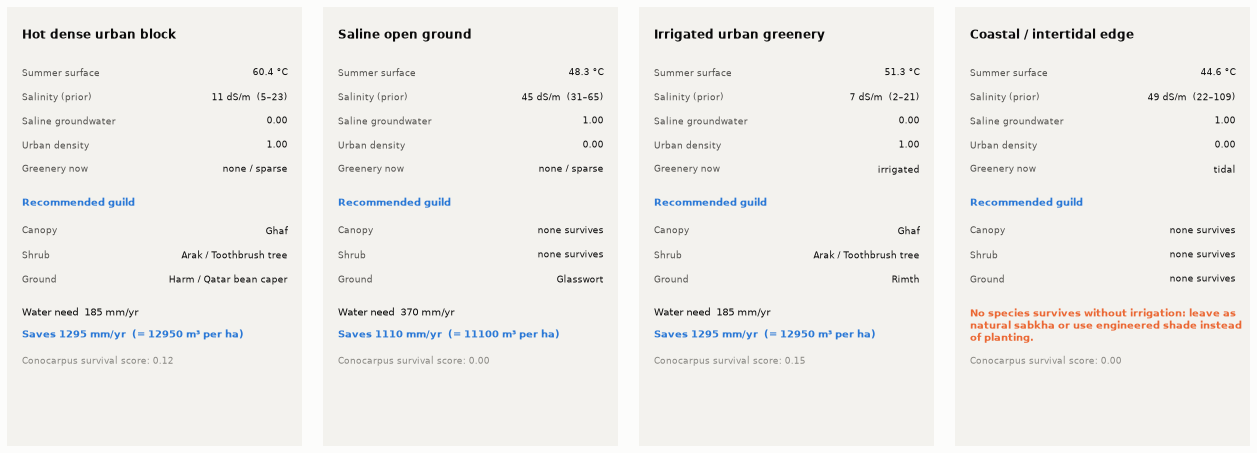

In [11]:
sites = report.pick_example_sites(fp, res)
reps = [report.site_report(fp, res, int(p[0]), int(p[1])) for _, p in sites]
fig = report.fig_site_cards(reps, [t for t, _ in sites]); viz.save(fig, "07_site_cards.png"); plt.show()

## 8 · Closing the loop with ground probes
Satellites see the surface; roots feel the soil. A ~USD 100 kit (EC 1:5 probe, pH probe, capacitive moisture, RS-485 NPK, IR thermometer,
phone GPS) measures what orbit cannot. The engine picks the sites where a reading would **change the most decisions**, and orders them
into a one-afternoon route.

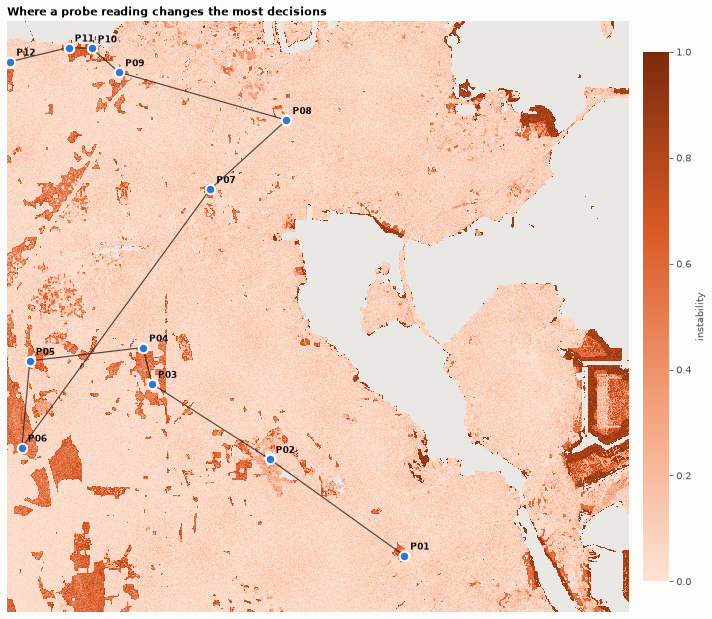

,visit_order,row,col,lon,lat,value,ece_prior_dSm,lst_c,irrigated_now,site_id
0,1,603,448,50.590,26.131,2.400,6.8,50.8,True,P01
1,2,494,296,50.559,26.151,2.400,7.9,44.9,True,P02
2,3,409,163,50.532,26.166,2.700,5.6,51.0,True,P03
3,4,368,153,50.530,26.174,2.400,7.1,49.0,True,P04
4,5,383,25,50.505,26.171,2.700,8.3,51.0,True,P05
5,6,481,16,50.503,26.153,2.400,5.9,51.3,True,P06
6,7,189,229,50.545,26.206,2.400,7.0,51.0,True,P07
7,8,111,315,50.563,26.220,2.400,7.2,50.8,True,P08
8,9,57,126,50.525,26.230,2.400,5.9,46.8,True,P09
9,10,30,95,50.519,26.235,2.475,7.8,47.2,True,P10


In [12]:
probes = uncertainty.select_probe_sites(fp, res, stability, profile, n_sites=run.n_probe_sites,
                                        min_spacing_m=run.probe_min_spacing_m, res_m=RES)
probes.to_csv(config.RESULTS_DIR / "probe_plan.csv", index=False)
fig = viz.fig_probes(fp, res, stability, probes); viz.save(fig, "08_probe_plan.png"); plt.show()
probes

### What-if: how one probe reading updates the map
**The readings below are hypothetical** (no field campaign has happened yet). They show the mechanism: a measured ECe and pH at the
first probe site are blended into the satellite prior (Gaussian-kernel residual correction, 600 m range), uncertainty shrinks around
the probe, and recommendations nearby are re-computed. Real readings go in `data/ground/ground_readings.csv` (template provided).

HYPOTHETICAL reading at P01: ECe 6.8 -> 20.3 dS/m, pH 8.6


Recommendations changed on 242 pixels (9.7 ha) around the probe


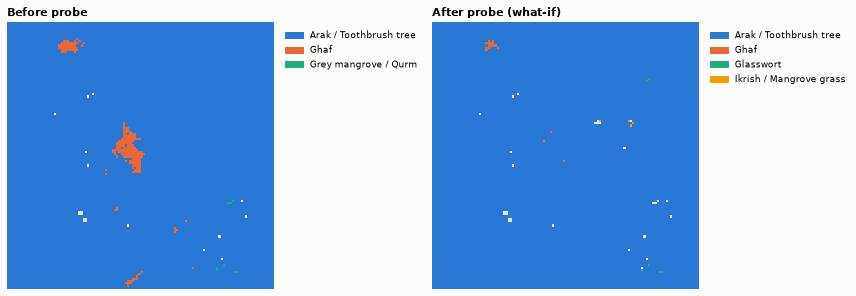

In [13]:
gpath = config.GROUND_DIR / "ground_readings.csv"
real = pd.read_csv(gpath) if gpath.exists() else pd.DataFrame()
if len(real):
    readings = uncertainty.prepare_readings(real, profile)
    print(f"Using {len(readings)} REAL ground readings from {gpath}")
else:
    p0 = probes.iloc[0]
    prior = float(fp["ECE"][int(p0.row), int(p0.col)])
    readings = pd.DataFrame([{"row": p0.row, "col": p0.col, "ece_dSm": prior * 3.0, "ph": 8.6}])
    print(f"HYPOTHETICAL reading at {p0.site_id}: ECe {prior:.1f} -> {prior*3:.1f} dS/m, pH 8.6")
fp2 = uncertainty.fuse_ground_readings(fp, readings, res_m=RES)
res2 = recommend.run_engine(fp2, kb, mask=res.mask)
changed = res2.hero != res.hero
print(f"Recommendations changed on {changed.sum():,} pixels ({changed.sum()*RES*RES/1e4:.1f} ha) around the probe")
r0, c0 = int(readings.iloc[0].row), int(readings.iloc[0].col)
win = np.s_[max(0, r0-60):r0+60, max(0, c0-60):c0+60]
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))
names = list(kb["common_name"])
viz.categorical_map(ax[0], res.to_2d(res.hero.astype("float32"), -1).astype(int)[win], names, "Before probe")
viz.categorical_map(ax[1], res2.to_2d(res2.hero.astype("float32"), -1).astype(int)[win], names, "After probe (what-if)")
fig.tight_layout(); viz.save(fig, "09_probe_whatif.png"); plt.show()

## 9 · Validation — what we can and cannot check today
There is no ground-truth map of "where each species survives" for Bahrain, so a single accuracy number would be misleading. Instead:
- **Independent reference check:** ESA WorldCover maps mangroves independently of our engine. Grey mangrove (*Avicennia marina*) should be a
  survivor there and nowhere inland.
- **Physical consistency:** greener pixels should be cooler in summer (negative LST–NDVI correlation).
- **Robustness:** Monte Carlo stability (section 5).
- **Regulatory sanity check:** Bahrain banned new Conocarpus planting in 2022 for infrastructure damage and water use; the model, which knows
  nothing about the ban, should rank it poorly in dense urban fabric.

In [14]:
from scipy.stats import spearmanr
wc = np.nan_to_num(layers["WORLDCOVER"]).astype(int)
qi = kb.index[kb.species_id == "qurm"][0]
qsurv = res.to_2d(res.surv[qi], 0.0)
mang = (wc == 95) & res.mask
val = {}
if mang.sum():
    val["WorldCover mangrove pixels where grey mangrove survives (%)"] = 100 * (qsurv[mang] >= config.SURVIVAL_THRESHOLD).mean()
inland = res.mask & (fp["DIST_SEA_M"] > 1000)
val["Inland (>1 km from sea) pixels where grey mangrove is recommended (%)"] = 100 * (res.to_2d(res.hero.astype('float32'), -1)[inland] == qi).mean()
ok = L & np.isfinite(fp["LST"]) & np.isfinite(fp["NDVI_SUMMER"])
rho = spearmanr(fp["NDVI_SUMMER"][ok], fp["LST"][ok]).statistic
val["Spearman rho, summer NDVI vs LST (expect < 0)"] = rho
ci = kb.index[kb.species_id == "conocarpus"][0]
dense = (fp["BUILT_DENSITY"][res.mask] > 0.6)
val["Conocarpus survives without routine irrigation in dense urban pixels (%)"] = 100 * (res.surv[ci][dense] >= config.SURVIVAL_THRESHOLD).mean()
val["Pixels with ≥1 surviving native species (%)"] = 100 * (res.n_survivors > 0).mean()
validation = pd.Series(val, name="value").round(2).to_frame(); validation

,value
WorldCover mangrove pixels where grey mangrove survives (%),100.00
Inland (>1 km from sea) pixels where grey mangrove is recommended (%),0.00
"Spearman rho, summer NDVI vs LST (expect < 0)",-0.07
Conocarpus survives without routine irrigation in dense urban pixels (%),0.00
Pixels with ≥1 surviving native species (%),99.99


## 10 · Save outputs

In [15]:
out = config.RESULTS_DIR
io.write_class_raster(out / "recommended_species.tif", res.to_2d(res.hero.astype("float32"), 255).astype("uint8"),
                      profile, labels=dict(enumerate(kb["common_name"])))
io.write_stack(out / "fingerprint_and_scores.tif", {
    "ECE_dSm": fp["ECE"], "LST_C": fp["LST"], "WATERLOG": fp["WATERLOG"], "VEG_PERSIST": fp["VEG_PERSIST"],
    "BUILT_DENSITY": fp["BUILT_DENSITY"], "WATER_NEED_mm": res.to_2d(res.water_mm), "SAVING_mm": res.to_2d(res.saving_mm),
    "STABILITY": res.to_2d(stability)}, profile["transform"], profile["crs"])   # int16 + scale tags
guilds.to_csv(out / "guilds.csv", index=False)
validation.to_csv(out / "validation.csv")
if transfer is not None:
    transfer.to_csv(out / "hyperspectral_transfer_cv.csv", index=False)
top = summary[~summary.comparison].head(5)
headline = {
    "aoi": meta["aoi"]["name"], "land_km2": float(L.sum() * RES * RES / 1e6),
    "irrigated_greenery_ha": float(fp["irrigated"].sum() * RES * RES / 1e4),
    "n_species": int(len(kb)), "n_native": int((kb.comparison == 0).sum()),
    "pct_land_with_native_survivor": float(100 * (res.n_survivors > 0).mean()),
    "top_species": top[["common_name", "recommended_pct_area"]].round(1).values.tolist(),
    "mean_saving_mm": float(np.nanmean(res.saving_mm)),
    "saving_mm_ci90": [float(lo), float(hi)],
    "water_budget": budget.round(1).to_dict(orient="records"),
    "median_stability": float(np.median(stability)),
    "pct_stable_80": float(100 * np.mean(stability >= 0.8)),
    "validation": {k: float(v) for k, v in val.items()},
    "transfer_cv": None if transfer is None else transfer.round(3).to_dict(orient="records"),
    "gypsum_transferred": gypsum_proxy is not None,
    "n_probe_sites": int(len(probes)),
    "data_period_summer": meta["sources"]["sentinel2_summer"]["period"],
    "n_s2_scenes_summer": meta["sources"]["sentinel2_summer"]["n_scenes"],
}
(out / "headline.json").write_text(json.dumps(headline, indent=2))
print(json.dumps({k: headline[k] for k in ["land_km2", "irrigated_greenery_ha", "pct_land_with_native_survivor",
                                            "mean_saving_mm", "median_stability"]}, indent=1))
sorted(p.name for p in out.iterdir())

{
 "land_km2": 149.5244,
 "irrigated_greenery_ha": 1107.8,
 "pct_land_with_native_survivor": 99.98662425664307,
 "mean_saving_mm": 1284.6431884765625,
 "median_stability": 0.925000011920929
}


['.gitkeep',
 '01_inputs.png',
 '02_fingerprint.png',
 '03_archetypes.png',
 '04_species_survival.png',
 '05_recommendation.png',
 '06_water_budget.png',
 '07_site_cards.png',
 '08_probe_plan.png',
 '09_probe_whatif.png',
 '10_hs_features_20250511_074311_00_4001.png',
 '10_hs_features_20250515_080954_16_4001.png',
 '10_hs_features_20250608_074757_58_4001.png',
 '11_hs_soil_spectra.png',
 '12_hs_transfer_r2.png',
 '13_hs_soil_confusion.png',
 'fingerprint_and_scores.tif',
 'guilds.csv',
 'headline.json',
 'hyperspectral_soil_recovery.json',
 'hyperspectral_transfer_cv.csv',
 'probe_plan.csv',
 'recommended_species.tif',
 'species_summary.csv',
 'validation.csv',
 'water_budget.csv']

## 11 · Limitations (read before using the maps)
- **Salinity is a satellite prior, not a measurement.** It blends spectral salinity indices, elevation and distance to sea, mapped to ECe
  with literature anchors (FAO AQUASTAT Bahrain). Under vegetation and buildings the spectra say little; uncertainty is mapped and fed to Monte Carlo.
- **Species tolerances** come from published trials and regional floras; several are expert estimates (marked `E` in the trait table) and need
  review by a Gulf horticulturist. Hydroponic NaCl tolerance overstates field tolerance, so comfort limits are deliberately conservative.
- **pH and nutrients are not observable from orbit**; a regional calcareous-soil prior is used until probes measure them.
- **20 m pixels mix** roads, roofs and verges. Recommendations are for the planting conditions typical of the pixel, not a specific tree pit.
- **Hyperspectral calibration uses Gulf analogue scenes**, not Bahrain; transfer across sites and between Tanager-simulated and real Sentinel-2
  reflectance adds error. Satellite 813 coverage of Bahrain would remove this step.
- **Irrigated-greenery detection** assumes summer-green, non-tidal vegetation is irrigated (Bahrain summer rainfall ≈ 0); date-palm farms are
  included in one water scenario and excluded from the urban replacement scenario.
- **Water savings** use WUCOLS-style plant factors × ET0 (1,850 mm/yr) and assume established plants; establishment-year irrigation is extra.